# Categorizing bank transactions with lazycontroller

A fast decision model (Jev) categorizes the transactions it is sure about; the rest go to the
slow model (GPT-6 Luna), as they would without lazycontroller. Both are reached through
[OpenRouter](https://openrouter.ai), so one key is enough.

Run it from the repository root, without adding Jupyter to the project:

```bash
uv run --with jupyterlab --with matplotlib --env-file .env jupyter lab examples/transactions.ipynb
```

with `OPENROUTER_API_KEY=...` in `.env`. The last section runs the same thing locally with
Ollama and is skipped if Ollama isn't running.

In [2]:
import os
from typing import Literal

from pydantic import BaseModel, Field

from lazycontroller import FastConfig, OpenAI, Route, ShadowReport

FAST = "typesafe/jev-1.14"
SLOW = "openai/gpt-6-luna"
KEY = os.environ["OPENROUTER_API_KEY"]

routes: list[Route] = []
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",  # the slow side: any OpenAI-compatible API
    api_key=KEY,
    max_retries=5,  # set to handle OpenRouter rate limiting: the SDK waits and retries
    fast=FastConfig(  # the fast side: a System One decision model
        base_url="https://openrouter.ai/api",
        api_key=KEY,
        model=FAST,
        min_confidence=0.9,  # every field must reach it, or the call goes to the slow model
        on_route=routes.append,
    ),
)


class Transaction(BaseModel):
    category: Literal[
        "groceries",
        "dining",
        "transport",
        "shopping",
        "subscriptions",
        "utilities",
        "income",
        "transfer",
    ] = Field(description="What the money was spent on, or where it came from")


def categorize(line: str, client=client):
    completion = client.chat.completions.parse(
        model=SLOW,
        messages=[
            {"role": "system", "content": "Categorize this bank transaction."},
            {"role": "user", "content": line},
        ],
        response_format=Transaction,
    )
    return completion.choices[0].message.parsed.category, completion.model

## 1. One call, two possible answerers

The code is what you would write with `openai`. Who answered shows in `completion.model`, and
the `Route` says why.

In [3]:
for line in ["NETFLIX.COM 866-579-7172 CA", "GITHUB, INC. SAN FRANCISCO"]:
    category, model = categorize(line)
    r = routes[-1]
    print(f"{line:<30} -> {category:<14} by {model:<30} {r.reason}, confidence {r.confidence:.2f}")

NETFLIX.COM 866-579-7172 CA    -> subscriptions  by typesafe/jev-1.14-20261014     confident, confidence 1.00
GITHUB, INC. SAN FRANCISCO     -> subscriptions  by openai/gpt-6-luna              low_confidence, confidence 0.77


## 2. Shadow mode: compare both models before trusting the fast one

With `shadow=True` both models answer every call and you always get the slow answer. Each route
records the fast model's confidence and whether the two agreed, which is what you need to pick
`min_confidence`.

The list mixes clear transactions with ambiguous ones: a payment to a person, a refund between
friends, a monthly transit pass (transport or subscription?), a phone bill (utilities or
subscription?). Sorted by confidence, the pattern is easy to see.

In [4]:
TRANSACTIONS = [
    "NETFLIX.COM 866-579-7172 CA",
    "AMZN MKTP IT*2K4L8 LUXEMBOURG",
    "POS 4412 ESSELUNGA MILANO",
    "UBER *TRIP HELP.UBER.COM",
    "SEPA CT ACME SRL STIPENDIO OTTOBRE",
    "PAYPAL *XYZSTORE 4029357733",
    "ENEL ENERGIA SDD 00123456",
    "POS 1234 BAR DA MARIO MI",
    "GITHUB, INC. SAN FRANCISCO",
    "GIROCONTO A FAVORE DI ROSSI MARIO",
    # harder ones
    "APPLE.COM/BILL ITUNES.COM",
    "PAYPAL *STEAM GAMES",
    "AUTOGRILL VILLORESI EST",
    "PRELIEVO BANCOMAT 3241",
    "TARI COMUNE DI MILANO",
    "SUMUP *LUCA B",
    "SATISPAY *MARIO ROSSI",
    "BONIFICO DA BIANCHI LUCA RIMBORSO CENA",
    "ATM MILANO ABBONAMENTO MENSILE",
    "IKEA FOOD MILANO",
    "SDD VODAFONE ITALIA",
    "CASHBACK CARTA VISA",
]

shadow = client.with_fast(shadow=True)
results = []
for line in TRANSACTIONS:
    category, _ = categorize(line, shadow)
    results.append((line, category, routes[-1]))

for line, category, r in sorted(results, key=lambda x: -x[2].confidence):
    verdict = "agree" if not r.shadow_mismatches else "DIFFER"
    fast = r.fast_output["category"]
    print(f"{r.confidence:.2f}  {verdict:<6}  {line:<40} fast: {fast:<14} slow: {category}")

1.00  agree   NETFLIX.COM 866-579-7172 CA              fast: subscriptions  slow: subscriptions
0.99  agree   AMZN MKTP IT*2K4L8 LUXEMBOURG            fast: shopping       slow: shopping
0.99  agree   UBER *TRIP HELP.UBER.COM                 fast: transport      slow: transport
0.99  agree   PAYPAL *XYZSTORE 4029357733              fast: shopping       slow: shopping
0.99  agree   ENEL ENERGIA SDD 00123456                fast: utilities      slow: utilities
0.98  agree   POS 4412 ESSELUNGA MILANO                fast: groceries      slow: groceries
0.97  agree   GIROCONTO A FAVORE DI ROSSI MARIO        fast: transfer       slow: transfer
0.97  agree   APPLE.COM/BILL ITUNES.COM                fast: subscriptions  slow: subscriptions
0.90  agree   POS 1234 BAR DA MARIO MI                 fast: dining         slow: dining
0.86  agree   AUTOGRILL VILLORESI EST                  fast: dining         slow: dining
0.85  agree   SEPA CT ACME SRL STIPENDIO OTTOBRE       fast: income         slow:

In [5]:
report = ShadowReport(r for _, _, r in results)
print(report.table())

22 shadow calls

confidence band   calls  agreement
  0.90-1.00           9  9/9 (100%)
  0.70-0.90           7  5/7 (71%)
  0.00-0.70           6  3/6 (50%)

min confidence   fast takes      agreement
  0.50           18/22 (82%)     15/18 (83%)
  0.60           17/22 (77%)     15/17 (88%)
  0.70           16/22 (73%)     14/16 (88%)
  0.80           12/22 (55%)     12/12 (100%)
  0.90           9/22 (41%)      9/9 (100%)


`ShadowReport.curve()` gives coverage and agreement for every `min_confidence` from 0 to 1,
ready to plot. The fast model's share of the traffic falls as `min_confidence` rises;
agreement climbs to 100% and stays there.

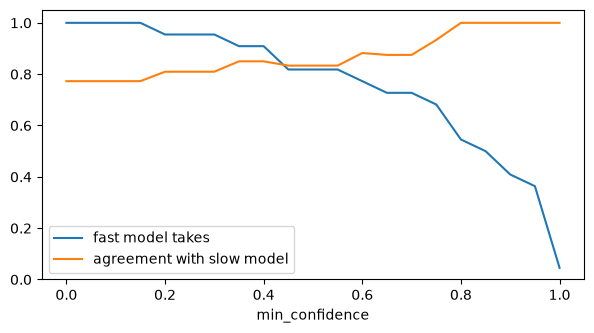

In [6]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Plotting needs matplotlib: start Jupyter with `uv run --with matplotlib ...`.")
else:
    curve = report.curve()
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(
        [p.min_confidence for p in curve], [p.coverage for p in curve], label="fast model takes"
    )
    ax.plot(
        [p.min_confidence for p in curve if p.taken],
        [p.agreement for p in curve if p.taken],
        label="agreement with slow model",
    )
    ax.set_xlabel("min_confidence")
    ax.set_ylim(0, 1.05)
    ax.legend()
    plt.show()

Finally, ask for the `min_confidence` that keeps the agreement you want.
`suggest_min_confidence()` returns the lowest value at which agreement stays at or above the
bar, from there up, and refuses to answer from too few calls (`min_samples`, 20 by default;
this example has only 22, so it's lowered here).

In [7]:
for bar in (1.0, 0.95, 0.9):
    t = report.suggest_min_confidence(min_agreement=bar, min_samples=10)
    if t is None:
        print(f"agreement >= {bar:.0%}: not enough data")
        continue
    p = report.at(t)
    print(f"agreement >= {bar:.0%}: min_confidence {t:.2f}, fast model takes {p.taken}/{p.total}")

agreement >= 100%: min_confidence 0.78, fast model takes 13/22
agreement >= 95%: min_confidence 0.78, fast model takes 13/22
agreement >= 90%: min_confidence 0.76, fast model takes 15/22


Agreement isn't correctness: in several of the disagreements above either answer is
defensible, and the exact numbers move a little from run to run. Look at the disagreements,
and collect more than a handful of calls, before choosing.

## 3. A different `min_confidence` for different code paths

`with_fast` derives a client with other `FastConfig` settings, like `with_options` does for the SDK.

In [8]:
cautious = client.with_fast(min_confidence=0.99)
for name, c in [("default 0.9", client), ("cautious 0.99", cautious)]:
    category, model = categorize("POS 1234 BAR DA MARIO MI", c)
    print(f"{name:<14} -> {category:<8} by {model}")

default 0.9    -> dining   by typesafe/jev-1.14-20261014
cautious 0.99  -> dining   by openai/gpt-6-luna


## 4. Calls that aren't decisions are left alone

A free-text field needs a generative model, so the whole call goes to the slow model untouched.

In [9]:
class Explained(Transaction):
    reason: str = Field(description="One sentence on why")


completion = client.chat.completions.parse(
    model=SLOW,
    messages=[{"role": "user", "content": "Categorize: NETFLIX.COM 866-579-7172 CA"}],
    response_format=Explained,
)
print(completion.choices[0].message.parsed)
print(routes[-1].reason, "-", routes[-1].detail)

category='subscriptions' reason='NETFLIX.COM is a streaming service subscription.'
ineligible - reason: free-text string


## 5. Everything local, with Ollama

`ollama pull kev:0.8b-q8_0 && ollama pull qwen3.5:4b`. A local server needs no key. Small local
decision models are far less sure of themselves, so most calls stay on the slow side.

In [10]:
import httpx2

try:
    httpx2.get("http://localhost:11434/api/version", timeout=2)
except httpx2.HTTPError:
    print("Ollama isn't running: skipped.")
else:
    local_routes: list[Route] = []
    local = OpenAI(
        base_url="http://localhost:11434/v1",
        fast=FastConfig(
            base_url="http://localhost:11434",
            model="kev:0.8b-q8_0",
            min_confidence=0.6,
            on_route=local_routes.append,
        ),
    )
    for line in TRANSACTIONS[:5]:
        completion = local.chat.completions.parse(
            model="qwen3.5:4b",
            messages=[
                {"role": "system", "content": "Categorize this bank transaction."},
                {"role": "user", "content": line},
            ],
            response_format=Transaction,
            reasoning_effort="none",
        )
        r = local_routes[-1]
        category = completion.choices[0].message.parsed.category
        print(
            f"{line:<36} -> {category:<14} by {completion.model:<14} confidence {r.confidence:.2f}"
        )

NETFLIX.COM 866-579-7172 CA          -> subscriptions  by qwen3.5:4b     confidence 0.36
AMZN MKTP IT*2K4L8 LUXEMBOURG        -> transfer       by qwen3.5:4b     confidence 0.56
POS 4412 ESSELUNGA MILANO            -> dining         by qwen3.5:4b     confidence 0.32
UBER *TRIP HELP.UBER.COM             -> transport      by kev:0.8b-q8_0  confidence 0.69
SEPA CT ACME SRL STIPENDIO OTTOBRE   -> transfer       by qwen3.5:4b     confidence 0.54
